In [2]:
!pip -q install pandas numpy matplotlib seaborn scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from pathlib import Path

print("GameStats backend initialized successfully!")

GameStats backend initialized successfully!


In [3]:
import io

csv_path = Path("game_stats.csv")

df = pd.read_csv(csv_path)
print("Loaded dataset from:", csv_path)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Loaded dataset from: game_stats.csv
Dataset shape: (300, 16)
Columns: ['Player', 'Game', 'Game_Mode', 'Kills', 'Deaths', 'Assists', 'Wins', 'Matches', 'Playtime_Hours', 'FPS_Avg', 'FPS_Min', 'CPU_Usage', 'GPU_Usage', 'RAM_Usage_GB', 'GPU_Temp', 'Score']


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score
0,Player_7,GTA 5,Story Mode,18,19,19,1,1,3.07,114,73,77,76,15.74,76,608
1,Player_20,GTA 5,Online,48,21,6,1,1,3.48,158,52,74,67,9.21,72,1761
2,Player_15,GTA 5,Race,35,5,3,0,1,2.95,37,55,23,44,9.92,66,2460
3,Player_11,GTA 5,Online,11,18,5,1,1,4.39,125,33,43,92,5.19,85,862
4,Player_8,GTA 5,Online,40,28,0,1,1,3.80,131,84,53,50,6.21,61,780


In [4]:
print("Dataset Shape:", df.shape)
print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (300, 16)

Data Types:
Player             object
Game               object
Game_Mode          object
Kills               int64
Deaths              int64
Assists             int64
Wins                int64
Matches             int64
Playtime_Hours    float64
FPS_Avg             int64
FPS_Min             int64
CPU_Usage           int64
GPU_Usage           int64
RAM_Usage_GB      float64
GPU_Temp            int64
Score               int64
dtype: object

First 5 Rows:


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score
0,Player_7,GTA 5,Story Mode,18,19,19,1,1,3.07,114,73,77,76,15.74,76,608
1,Player_20,GTA 5,Online,48,21,6,1,1,3.48,158,52,74,67,9.21,72,1761
2,Player_15,GTA 5,Race,35,5,3,0,1,2.95,37,55,23,44,9.92,66,2460
3,Player_11,GTA 5,Online,11,18,5,1,1,4.39,125,33,43,92,5.19,85,862
4,Player_8,GTA 5,Online,40,28,0,1,1,3.80,131,84,53,50,6.21,61,780



Last 5 Rows:


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score
295,Player_1,GTA 5,Deathmatch,26,20,6,1,1,1.10,159,90,82,88,15.87,83,761
296,Player_20,GTA 5,Deathmatch,28,15,2,1,1,1.15,49,23,86,76,6.11,50,2408
297,Player_1,GTA 5,Story Mode,31,15,2,0,1,4.73,39,33,23,46,9.90,45,186
298,Player_3,GTA 5,Online,49,29,17,0,1,3.80,54,22,77,51,11.46,67,2223
299,Player_18,GTA 5,Story Mode,50,1,4,1,1,1.23,54,99,44,97,11.38,83,1408



Missing Values:
Player            0
Game              0
Game_Mode         0
Kills             0
Deaths            0
Assists           0
Wins              0
Matches           0
Playtime_Hours    0
FPS_Avg           0
FPS_Min           0
CPU_Usage         0
GPU_Usage         0
RAM_Usage_GB      0
GPU_Temp          0
Score             0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score
count,300.000000,300.000000,300.000000,300.000000,300.0,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,24.380000,14.883333,9.723333,0.466667,1.0,2.723633,106.173333,55.560000,57.820000,66.536667,9.711733,67.796667,1278.616667
std,14.881773,8.744404,6.279988,0.499721,0.0,1.279350,45.210063,23.581065,21.971118,19.300008,3.760366,13.140684,713.591779
min,0.000000,1.000000,0.000000,0.000000,1.0,0.500000,30.000000,20.000000,20.000000,30.000000,3.030000,45.000000,118.000000
25%,11.000000,7.000000,4.000000,0.000000,1.0,1.567500,66.000000,35.000000,39.000000,50.000000,6.427500,56.000000,666.750000
50%,24.500000,15.000000,9.000000,0.000000,1.0,2.790000,104.500000,51.500000,58.000000,68.000000,10.140000,68.000000,1270.500000
75%,37.000000,23.000000,16.000000,1.000000,1.0,3.792500,147.000000,76.250000,77.000000,82.000000,12.725000,79.250000,1913.500000
max,50.000000,30.000000,20.000000,1.000000,1.0,4.960000,180.000000,100.000000,95.000000,100.000000,16.000000,89.000000,2486.000000


In [5]:

df = df.drop_duplicates().copy()

# Replace invalid values with NaN
df.loc[df["FPS_Avg"] <= 0, "FPS_Avg"] = np.nan
df.loc[df["FPS_Min"] <= 0, "FPS_Min"] = np.nan

numeric_cols = df.select_dtypes(include="number").columns

df[numeric_cols] = df[numeric_cols].fillna(
    df[numeric_cols].median()
)

categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Data cleaning completed!")
print("Missing values remaining:", df.isnull().sum().sum())

Data cleaning completed!
Missing values remaining: 0


In [7]:
df["KDA"] = (
    df["Kills"] + df["Assists"]
) / df["Deaths"].replace(0, np.nan)

df["KDA"] = df["KDA"].fillna(0)

df["Win_Rate"] = (
    df["Wins"] / df["Matches"]
) * 100

df["FPS_Category"] = pd.cut(
    df["FPS_Avg"],
    bins=[0, 60, 120, 180, float("inf")],
    labels=["Low", "Moderate", "High", "Very High"]
)

print("Performance metrics calculated!")
display(df[[
    "Player", "Game_Mode", "Kills", "Deaths",
    "Assists", "KDA", "Win_Rate",
    "FPS_Avg", "FPS_Category"
]].head(10))

Performance metrics calculated!


,Player,Game_Mode,Kills,Deaths,Assists,KDA,Win_Rate,FPS_Avg,FPS_Category
0,Player_7,Story Mode,18,19,19,1.947368,100.0,114.0,Moderate
1,Player_20,Online,48,21,6,2.571429,100.0,158.0,High
2,Player_15,Race,35,5,3,7.600000,0.0,37.0,Low
3,Player_11,Online,11,18,5,0.888889,100.0,125.0,High
4,Player_8,Online,40,28,0,1.428571,100.0,131.0,High
5,Player_7,Race,18,10,4,2.200000,100.0,34.0,Low
6,Player_19,Deathmatch,11,29,0,0.379310,100.0,115.0,Moderate
7,Player_11,Online,8,22,3,0.500000,0.0,63.0,Moderate
8,Player_11,Deathmatch,6,21,1,0.333333,0.0,84.0,Moderate
9,Player_4,Online,27,6,9,6.000000,100.0,148.0,High


In [8]:
columns = [
    "FPS_Avg", "FPS_Min", "CPU_Usage",
    "GPU_Usage", "RAM_Usage_GB",
    "GPU_Temp", "Score"
]

stats = pd.DataFrame({
    "Mean": df[columns].mean(),
    "Median": df[columns].median(),
    "Mode": df[columns].mode().iloc[0],
    "Variance": df[columns].var(),
    "Standard_Deviation": df[columns].std(),
    "Skewness": df[columns].skew(),
    "25th_Percentile": df[columns].quantile(0.25),
    "75th_Percentile": df[columns].quantile(0.75)
})

display(stats.round(2))

,Mean,Median,Mode,Variance,Standard_Deviation,Skewness,25th_Percentile,75th_Percentile
FPS_Avg,106.17,104.50,131.00,2043.95,45.21,0.02,66.00,147.00
FPS_Min,55.56,51.50,40.00,556.07,23.58,0.25,35.00,76.25
CPU_Usage,57.82,58.00,89.00,482.73,21.97,-0.01,39.00,77.00
GPU_Usage,66.54,68.00,48.00,372.49,19.30,-0.10,50.00,82.00
RAM_Usage_GB,9.71,10.14,10.14,14.14,3.76,-0.15,6.43,12.72
GPU_Temp,67.80,68.00,85.00,172.68,13.14,-0.09,56.00,79.25
Score,1278.62,1270.50,142.00,509213.23,713.59,0.06,666.75,1913.50


In [9]:
game_mode_stats = df.groupby("Game_Mode").agg({
    "FPS_Avg": "mean",
    "FPS_Min": "mean",
    "CPU_Usage": "mean",
    "GPU_Usage": "mean",
    "RAM_Usage_GB": "mean",
    "GPU_Temp": "mean",
    "Score": "mean",
    "Kills": "sum",
    "Wins": "sum",
    "Matches": "sum"
}).round(2)

print("Game Mode Performance Analysis:")
display(game_mode_stats)

print("\nNumber of sessions per mode:")
display(df["Game_Mode"].value_counts())

Game Mode Performance Analysis:


,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score,Kills,Wins,Matches
Game_Mode,,,,,,,,,,
Deathmatch,107.06,52.92,56.73,67.69,9.94,65.21,1255.58,1740,42,78
Online,112.75,56.93,63.33,62.52,9.90,67.72,1395.49,1952,34,81
Race,101.82,52.02,55.61,66.10,9.43,70.15,1229.55,1571,25,62
Story Mode,101.96,59.54,54.97,69.86,9.51,68.59,1220.04,2051,39,79



Number of sessions per mode:


,count
Game_Mode,
Online,81
Story Mode,79
Deathmatch,78
Race,62


In [10]:
leaderboard = df.groupby("Player").agg({
    "Kills": "sum",
    "Deaths": "sum",
    "Assists": "sum",
    "Wins": "sum",
    "Matches": "sum",
    "Score": "mean",
    "FPS_Avg": "mean"
})

leaderboard["KDA"] = (
    leaderboard["Kills"] + leaderboard["Assists"]
) / leaderboard["Deaths"].replace(0, np.nan)

leaderboard["Win_Rate"] = (
    leaderboard["Wins"] / leaderboard["Matches"]
) * 100

leaderboard = leaderboard.sort_values(
    "Score", ascending=False
).round(2)

print("Top 10 Players by Average Score:")
display(leaderboard.head(10))

Top 10 Players by Average Score:


,Kills,Deaths,Assists,Wins,Matches,Score,FPS_Avg,KDA,Win_Rate
Player,,,,,,,,,
Player_17,389,251,169,9,17,1500.35,127.59,2.22,52.94
Player_7,513,326,233,10,19,1482.11,120.63,2.29,52.63
Player_6,245,110,124,4,12,1471.33,109.08,3.35,33.33
Player_20,468,238,153,9,18,1399.50,113.89,2.61,50.00
Player_15,387,210,137,9,14,1346.64,110.93,2.50,64.29
Player_4,265,262,180,9,14,1328.57,124.29,1.70,64.29
Player_14,304,163,92,5,11,1321.00,105.64,2.43,45.45
Player_12,536,284,167,7,17,1291.59,111.82,2.48,41.18
Player_3,590,336,243,9,24,1290.21,100.67,2.48,37.50


In [11]:
print("Top 5 Sessions by Average FPS:")
display(df.nlargest(5, "FPS_Avg"))

print("\nTop 5 Sessions by Score:")
display(df.nlargest(5, "Score"))

print("\nTop 5 Sessions by GPU Temperature:")
display(df.nlargest(5, "GPU_Temp"))

Top 5 Sessions by Average FPS:


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score,KDA,Win_Rate,FPS_Category
88,Player_5,GTA 5,Deathmatch,0,25,10,0,1,1.90,180.0,100.0,35,48,9.87,61,1915,0.400000,0.0,High
264,Player_17,GTA 5,Online,3,8,3,1,1,2.90,180.0,73.0,52,63,10.48,65,2450,0.750000,100.0,High
272,Player_13,GTA 5,Deathmatch,33,23,0,1,1,4.94,180.0,94.0,94,59,12.61,78,2430,1.434783,100.0,High
141,Player_7,GTA 5,Deathmatch,40,23,2,0,1,2.06,179.0,43.0,89,66,12.87,45,1188,1.826087,0.0,High
169,Player_17,GTA 5,Online,17,19,4,0,1,2.68,179.0,68.0,34,54,10.72,67,2201,1.105263,0.0,High



Top 5 Sessions by Score:


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score,KDA,Win_Rate,FPS_Category
39,Player_20,GTA 5,Race,9,17,7,0,1,2.45,131.0,29.0,66,67,10.14,65,2486,0.941176,0.0,High
89,Player_10,GTA 5,Online,2,17,5,0,1,1.94,136.0,79.0,73,55,13.31,87,2485,0.411765,0.0,High
64,Player_8,GTA 5,Race,24,14,7,1,1,4.18,40.0,82.0,23,64,13.49,75,2478,2.214286,100.0,Low
98,Player_16,GTA 5,Deathmatch,44,18,6,1,1,1.22,44.0,71.0,69,33,3.90,74,2469,2.777778,100.0,Low
216,Player_7,GTA 5,Race,33,24,12,1,1,4.07,115.0,94.0,20,67,5.42,47,2466,1.875000,100.0,Moderate



Top 5 Sessions by GPU Temperature:


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score,KDA,Win_Rate,FPS_Category
12,Player_2,GTA 5,Online,18,9,0,0,1,4.69,55.0,32.0,82,35,6.06,89,1638,2.000000,0.0,Low
56,Player_18,GTA 5,Online,18,14,4,0,1,3.54,172.0,23.0,83,31,14.94,89,474,1.571429,0.0,High
135,Player_13,GTA 5,Story Mode,25,30,5,0,1,1.16,149.0,96.0,62,68,13.95,89,844,1.000000,0.0,High
158,Player_9,GTA 5,Story Mode,4,30,0,1,1,1.06,48.0,83.0,29,74,8.22,89,916,0.133333,100.0,Low
167,Player_17,GTA 5,Deathmatch,32,8,3,1,1,4.03,148.0,69.0,45,98,13.18,89,469,4.375000,100.0,High


Correlation Matrix:


,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score,Kills,Deaths
FPS_Avg,1.00,0.10,0.03,-0.06,-0.08,0.03,0.16,-0.05,0.16
FPS_Min,0.10,1.00,-0.04,0.04,0.01,-0.01,-0.01,-0.10,0.01
CPU_Usage,0.03,-0.04,1.00,-0.04,0.00,0.04,-0.01,-0.04,0.02
GPU_Usage,-0.06,0.04,-0.04,1.00,-0.04,-0.03,-0.02,0.02,-0.04
RAM_Usage_GB,-0.08,0.01,0.00,-0.04,1.00,0.05,-0.00,0.01,0.08
GPU_Temp,0.03,-0.01,0.04,-0.03,0.05,1.00,-0.04,-0.08,-0.00
Score,0.16,-0.01,-0.01,-0.02,-0.00,-0.04,1.00,0.01,-0.02
Kills,-0.05,-0.10,-0.04,0.02,0.01,-0.08,0.01,1.00,-0.03
Deaths,0.16,0.01,0.02,-0.04,0.08,-0.00,-0.02,-0.03,1.00


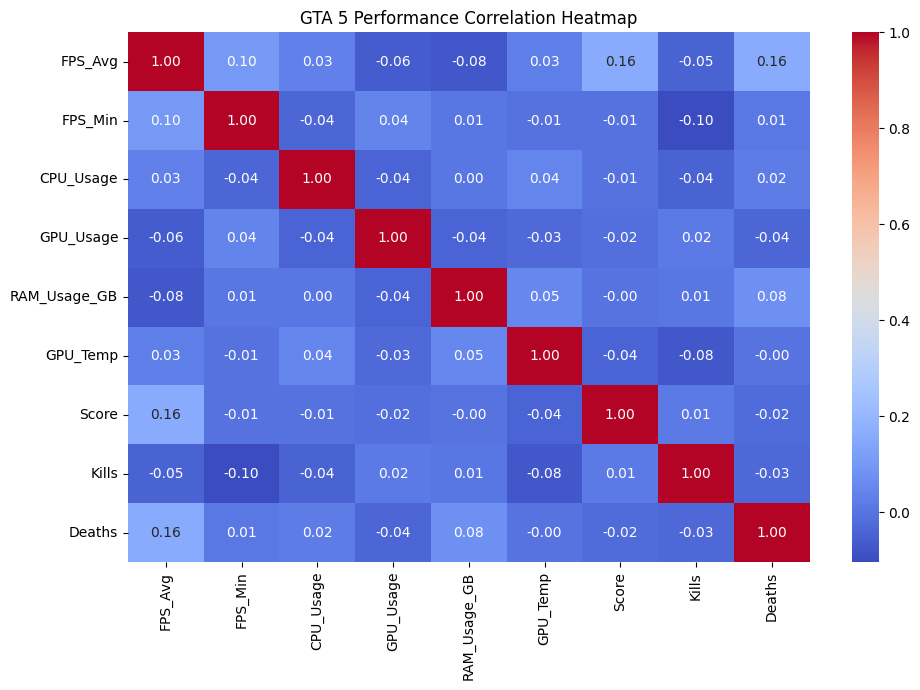

In [12]:
correlation_cols = [
    "FPS_Avg", "FPS_Min", "CPU_Usage",
    "GPU_Usage", "RAM_Usage_GB",
    "GPU_Temp", "Score", "Kills", "Deaths"
]

correlation_matrix = df[correlation_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("GTA 5 Performance Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
r, p_value = pearsonr(df["FPS_Avg"], df["Score"])

print("Pearson Correlation using SciPy:", round(r, 4))
print("P-value:", round(p_value, 4))

x = df["FPS_Avg"]
y = df["Score"]

manual_r = (
    ((x - x.mean()) * (y - y.mean())).sum()
    /
    np.sqrt(
        ((x - x.mean()) ** 2).sum()
        * ((y - y.mean()) ** 2).sum()
    )
)

print("Pearson Correlation calculated manually:", round(manual_r, 4))

Pearson Correlation using SciPy: 0.1572
P-value: 0.0064
Pearson Correlation calculated manually: 0.1572


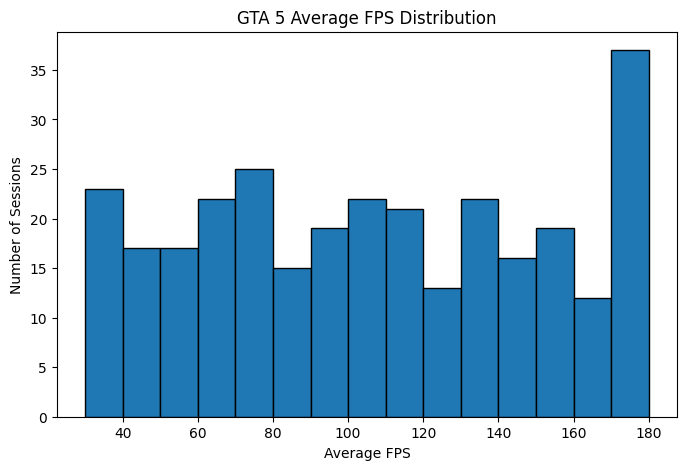

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["FPS_Avg"], bins=15, edgecolor="black")
plt.title("GTA 5 Average FPS Distribution")
plt.xlabel("Average FPS")
plt.ylabel("Number of Sessions")
plt.show()

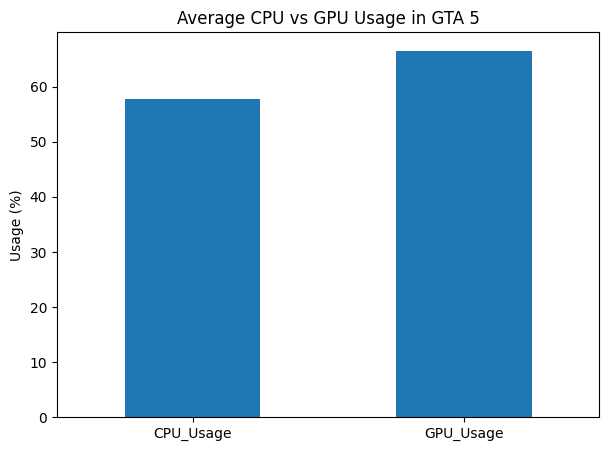

In [15]:
usage = df[["CPU_Usage", "GPU_Usage"]].mean()

usage.plot(kind="bar", figsize=(7, 5))
plt.title("Average CPU vs GPU Usage in GTA 5")
plt.ylabel("Usage (%)")
plt.xticks(rotation=0)
plt.show()

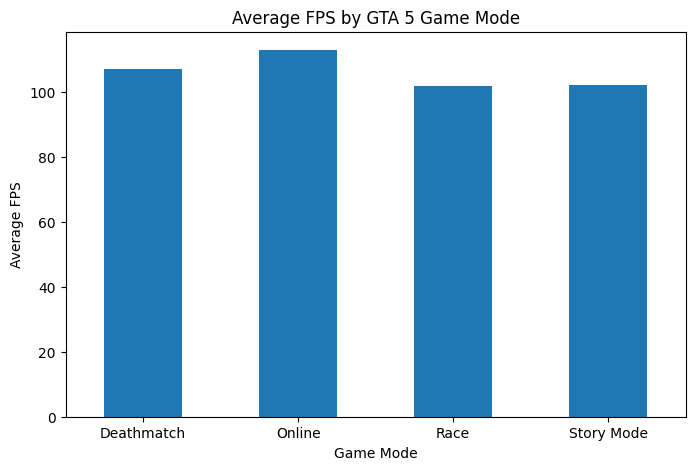

In [16]:
df.groupby("Game_Mode")["FPS_Avg"].mean().plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Average FPS by GTA 5 Game Mode")
plt.xlabel("Game Mode")
plt.ylabel("Average FPS")
plt.xticks(rotation=0)
plt.show()

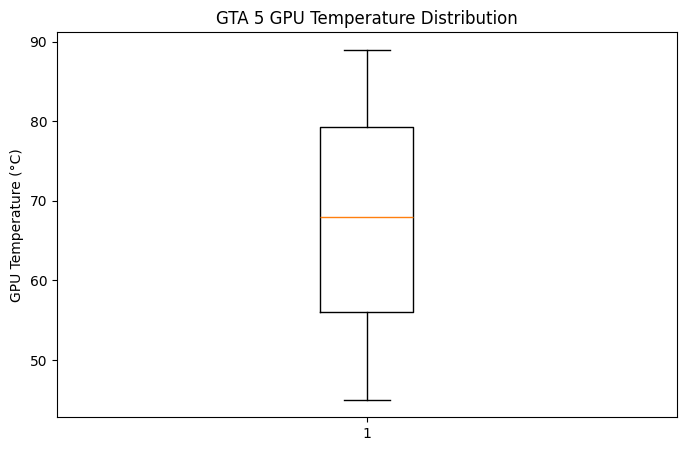

In [17]:
plt.figure(figsize=(8, 5))
plt.boxplot(df["GPU_Temp"])
plt.title("GTA 5 GPU Temperature Distribution")
plt.ylabel("GPU Temperature (°C)")
plt.show()

In [18]:
df.to_csv("gta5_cleaned_data.csv", index=False)

leaderboard.to_csv("gta5_player_leaderboard.csv")

game_mode_stats.to_csv("gta5_game_mode_analysis.csv")

correlation_matrix.to_csv("gta5_correlation_matrix.csv")

stats.to_csv("gta5_descriptive_statistics.csv")

print("All GTA 5 reports exported successfully!")

All GTA 5 reports exported successfully!


In [19]:
print("=" * 45)
print("       GAMESTATS - GTA 5 ANALYZER")
print("=" * 45)

print("Total sessions analyzed:", len(df))
print("Total unique players:", df["Player"].nunique())

print("Overall average FPS:", round(df["FPS_Avg"].mean(), 2))
print("Overall minimum FPS:", df["FPS_Min"].min())
print("Average CPU usage:", round(df["CPU_Usage"].mean(), 2), "%")
print("Average GPU usage:", round(df["GPU_Usage"].mean(), 2), "%")
print("Average RAM usage:", round(df["RAM_Usage_GB"].mean(), 2), "GB")
print("Average GPU temperature:", round(df["GPU_Temp"].mean(), 2), "°C")

if df["Score"].notna().any():
    print("Highest session score:", df["Score"].max())
    print("\nTop performing session:")
    display(df.nlargest(1, "Score"))
else:
    print("Highest session score: Not available")

if df["FPS_Avg"].notna().any():
    print("Highest average FPS:", df["FPS_Avg"].max())
else:
    print("Highest average FPS: Not available")

print("\nProject analysis completed!")
print("=" * 45)

       GAMESTATS - GTA 5 ANALYZER
Total sessions analyzed: 300
Total unique players: 20
Overall average FPS: 106.17
Overall minimum FPS: 20.0
Average CPU usage: 57.82 %
Average GPU usage: 66.54 %
Average RAM usage: 9.71 GB
Average GPU temperature: 67.8 °C
Highest session score: 2486

Top performing session:


,Player,Game,Game_Mode,Kills,Deaths,Assists,Wins,Matches,Playtime_Hours,FPS_Avg,FPS_Min,CPU_Usage,GPU_Usage,RAM_Usage_GB,GPU_Temp,Score,KDA,Win_Rate,FPS_Category
39,Player_20,GTA 5,Race,9,17,7,0,1,2.45,131.0,29.0,66,67,10.14,65,2486,0.941176,0.0,High


Highest average FPS: 180.0

Project analysis completed!
